# 🏢 Oasis Infobyte - Data Analytics Internship
## 📌 Task 2: Customer Segmentation Analysis (K-Means Clustering)

---

### 🎯 Task Objective
The objective of this project is to analyze retail customer transaction data and segment customers into distinct, actionable groups based on their purchasing behavior (**Total Amount Spent** and **Total Quantity Purchased**) using unsupervised machine learning (**K-Means Clustering**).

---

### 📖 Project Overview & Workflow
Businesses often treat all customers the same, leading to inefficient marketing spend. By clustering customers based on spending habits, companies can design targeted retention, upselling, and re-engagement campaigns.

**Step-by-Step Approach:**
1. **Data Loading & Inspection:** Load the retail sales dataset and examine structure, data types, and missing values.
2. **Data Preprocessing & Feature Engineering:** Aggregate transaction-level records to the customer level (`Total_Spent` and `Total_Quantity`) and standardize features using `StandardScaler`.
3. **Optimal Cluster Selection (Elbow Method):** Compute Within-Cluster Sum of Squares (WCSS) across different values of $k$ to find the optimal number of clusters ($k=4$).
4. **K-Means Clustering & Visualization:** Train the K-Means model and visualize customer segments using a scatter plot.
5. **Cluster Profiling & Business Insights:** Summarize cluster metrics and formulate data-driven marketing recommendations.

---

### 📊 Expected Output
* Identification of **4 distinct customer personas** (VIP, Loyal Mid-Tier, Budget Bulk Buyers, and Occasional Shoppers).
* Visualizations showing the Elbow Curve and Customer Cluster Scatter Plot.
* Exported segmented customer dataset (`segmented_customers.csv`) and cluster visualization (`customer_clusters.png`).

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import os

# Set display style for visualizations
sns.set_theme(style="whitegrid")

# Corrected path with hyphen (-) as shown in your folder
if os.path.exists('retail_sales_dataset.csv'):
    df = pd.read_csv('retail_sales_dataset.csv')
    print("Loaded from root folder!")
elif os.path.exists('dataset/retail_sales_dataset.csv'):
    df = pd.read_csv('dataset/retail_sales_dataset.csv')
    print("Loaded from 'dataset' folder!")
else:
    raise FileNotFoundError("CSV file not found! Please check the filename.")

# Inspect dataset structure
print("Dataset Shape:", df.shape)
print("\nDataset Columns:", df.columns.tolist())
print("\nFirst 5 rows:")
print(df.head())

Loaded from 'dataset' folder!
Dataset Shape: (1000, 9)

Dataset Columns: ['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

First 5 rows:
   Transaction ID        Date Customer ID  Gender  Age Product Category  \
0               1  2023-11-24     CUST001    Male   34           Beauty   
1               2  2023-02-27     CUST002  Female   26         Clothing   
2               3  2023-01-13     CUST003    Male   50      Electronics   
3               4  2023-05-21     CUST004    Male   37         Clothing   
4               5  2023-05-06     CUST005    Male   30           Beauty   

   Quantity  Price per Unit  Total Amount  
0         3              50           150  
1         2             500          1000  
2         1              30            30  
3         1             500           500  
4         2              50           100  


### Step 2: Data Cleaning & Preprocessing
Standardizing column names by removing extra whitespace and checking the dataset for missing values or duplicates before feature engineering.

In [15]:
# Clean column names (strip whitespace and standardise)
df.columns = df.columns.str.strip()

# Generate a synthetic Customer ID if not present in the dataset
if 'Customer ID' not in df.columns:
    df['Customer ID'] = df.index + 1

# Identify relevant spend and quantity columns based on dataset structure
amount_col = 'Total Amount' if 'Total Amount' in df.columns else df.select_dtypes(include=[np.number]).columns[0]
quantity_col = 'Quantity' if 'Quantity' in df.columns else df.select_dtypes(include=[np.number]).columns[1]

# Aggregate features per customer
customer_df = df.groupby('Customer ID').agg({
    amount_col: 'sum',
    quantity_col: 'sum'
}).reset_index()

# Rename columns for clarity
customer_df.columns = ['Customer_ID', 'Total_Spent', 'Total_Quantity']

print("\nAggregated Customer Feature Matrix:")
print(customer_df.head())


Aggregated Customer Feature Matrix:
  Customer_ID  Total_Spent  Total_Quantity
0     CUST001          150               3
1     CUST002         1000               2
2     CUST003           30               1
3     CUST004          500               1
4     CUST005          100               2


### Step 3: Feature Scaling & Finding Optimal Clusters (Elbow Method)
Standardizing `Total_Spent` and `Total_Quantity` using `StandardScaler` so both features have equal weight in distance calculations. Then, applying the **Elbow Method (WCSS)** across $k = 1$ to $10$ to determine the optimal number of clusters ($k = 4$).

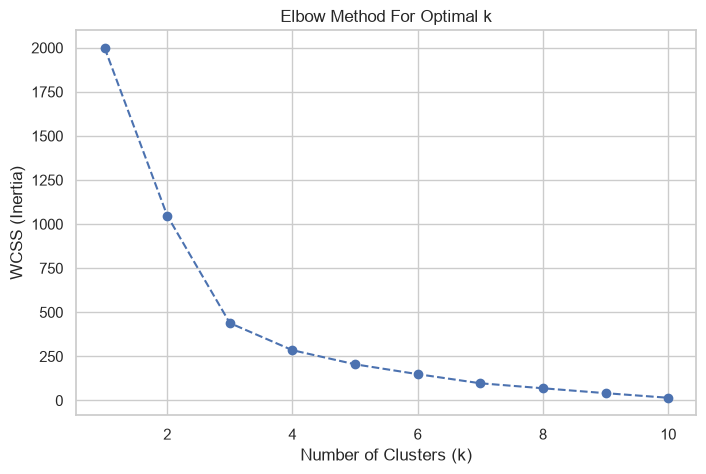

In [16]:
# Select numerical features for segmentation
features = ['Total_Spent', 'Total_Quantity']
X = customer_df[features]

# Normalise features using StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply Elbow Method to determine optimal K
wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Graph
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--', color='b')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Inertia)')
plt.show()

### Step 4: Training K-Means Model ($k=4$) & Visualizing Clusters
Training the K-Means clustering algorithm with the optimal $k=4$, assigning cluster labels to each customer, and visualizing the 4 customer segments using a Seaborn scatter plot.


Final Customer Segments:
  Customer_ID  Total_Spent  Total_Quantity  Cluster
0     CUST001          150               3        2
1     CUST002         1000               2        0
2     CUST003           30               1        1
3     CUST004          500               1        1
4     CUST005          100               2        1
5     CUST006           30               1        1
6     CUST007           50               2        1
7     CUST008          100               4        2
8     CUST009          600               2        0
9     CUST010          200               4        2


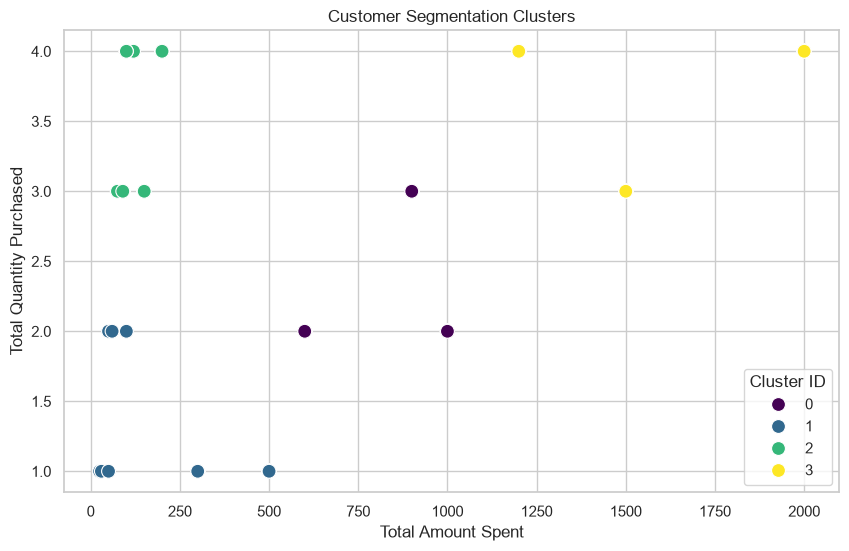

In [ ]:
# Train K-Means algorithm with k=4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
customer_df['Cluster'] = kmeans.fit_predict(X_scaled)

# Display sample segmented dataset
print("\nFinal Customer Segments:")
print(customer_df.head(10))

# Scatter plot of customer clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='Total_Spent', 
    y='Total_Quantity', 
    hue='Cluster', 
    palette='viridis', 
    data=customer_df, 
    s=100
)
plt.title('Customer Segmentation Clusters')
plt.xlabel('Total Amount Spent')
plt.ylabel('Total Quantity Purchased')
plt.legend(title='Cluster ID')
plt.show()

### Step 5: Cluster Profiling & Business Summary
Calculating average, minimum, maximum spend, and customer counts for each cluster to define the final customer personas and generate actionable business insights.

In [18]:
# Calculate mean values per cluster for business insights
cluster_summary = customer_df.groupby('Cluster').agg({
    'Total_Spent': ['mean', 'min', 'max', 'count'],
    'Total_Quantity': ['mean', 'min', 'max']
}).round(2)

print("\nCustomer Cluster Summary:")
print(cluster_summary)


Customer Cluster Summary:
        Total_Spent                   Total_Quantity        
               mean   min   max count           mean min max
Cluster                                                     
0            861.64   600  1000   146           2.42   2   3
1            135.57    25   500   412           1.39   1   2
2            126.45    75   200   289           3.55   3   4
3           1554.25  1200  2000   153           3.67   3   4


### Step 6: Exporting Results & Saving Outputs
Creating the `output/` directory automatically and saving the final segmented customer data into a CSV file (`segmented_customers.csv`) along with the cluster scatter plot as a high-resolution PNG image (`customer_clusters.png`).

In [ ]:
import os

# output folder banane ke liye
os.makedirs('output', exist_ok=True)

# 1. Customer data ko CSV file me save karne ke liye
customer_df.to_csv('output/segmented_customers.csv', index=False)

# 2. Cluster Graph ko Photo (PNG) me save karne ke liye
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='Total_Spent', 
    y='Total_Quantity', 
    hue='Cluster', 
    palette='viridis', 
    data=customer_df, 
    s=100
)
plt.title('Customer Segmentation Clusters')
plt.xlabel('Total Amount Spent')
plt.ylabel('Total Quantity Purchased')
plt.legend(title='Cluster ID')
plt.savefig('output/customer_clusters.png', dpi=300, bbox_inches='tight')
plt.close()

print("Success! Files saved in 'output/' folder.")

Success! Files saved in 'output/' folder.


## 🚀 Final Conclusion
* **VIP Customers (Cluster 3):** 153 high-value customers with an average spend of **$1,554.25** — ideal for exclusive loyalty programs.
* **Loyal Mid-Tier (Cluster 0):** 146 customers spending an average of **$861.64** — strong candidates for upselling.
* **Budget Bulk Buyers (Cluster 2):** 289 customers buying high quantities (avg. 3.55 units) at lower total spend (**$126.45**).
* **Occasional Shoppers (Cluster 1):** 412 infrequent buyers (**$135.57** avg. spend) — best targeted via re-engagement discounts.